# Assess: resultados por fuente, errores y funcionamiento real

VulnMiner · DavidPilaguano · SEMMA con datos públicos verificables.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'data/dataset.csv').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
df = pd.read_csv(ROOT / 'data/dataset.csv', keep_default_na=False)
df['labels'] = df.labels.map(json.loads)
manifest = json.loads((ROOT / 'data/public_manifest.json').read_text(encoding='utf-8'))
results = json.loads((ROOT / 'output/evaluation/metrics.json').read_text(encoding='utf-8'))
selected = results['candidates'][results['selected']]


La evaluación separa el clasificador sobre fragmentos preparados, la CLI sobre fuentes originales y las fixtures funcionales. Se reportan F1 macro/micro, precisión, recall y matrices binarias por etiqueta. No se interpreta confianza como severidad ni como probabilidad calibrada.

,precision,recall,f1-score,support
A01:2025,0.508197,0.720930,0.596154,43.0
A02:2025,0.652174,0.714286,0.681818,21.0
A04:2025,0.852459,1.000000,0.920354,104.0
A05:2025,0.847682,0.992248,0.914286,129.0
A06:2025,0.636364,1.000000,0.777778,14.0
A07:2025,0.800000,1.000000,0.888889,24.0
A08:2025,0.666667,1.000000,0.800000,14.0
API10:2023,0.666667,1.000000,0.800000,12.0
API2:2023,1.000000,1.000000,1.000000,12.0
API7:2023,0.000000,0.000000,0.000000,12.0


,fuente,registros,F1_macro_etiquetas_con_soporte,F1_micro
0,BenchmarkJava,389,0.804557,0.881057
1,BenchmarkPython,178,0.761130,0.785276
2,original-controlled-v1,168,0.715556,0.809524


Entrenamiento / validación / prueba: [0.9085483566257092, 0.9275284279812236, 0.7617525810204812]


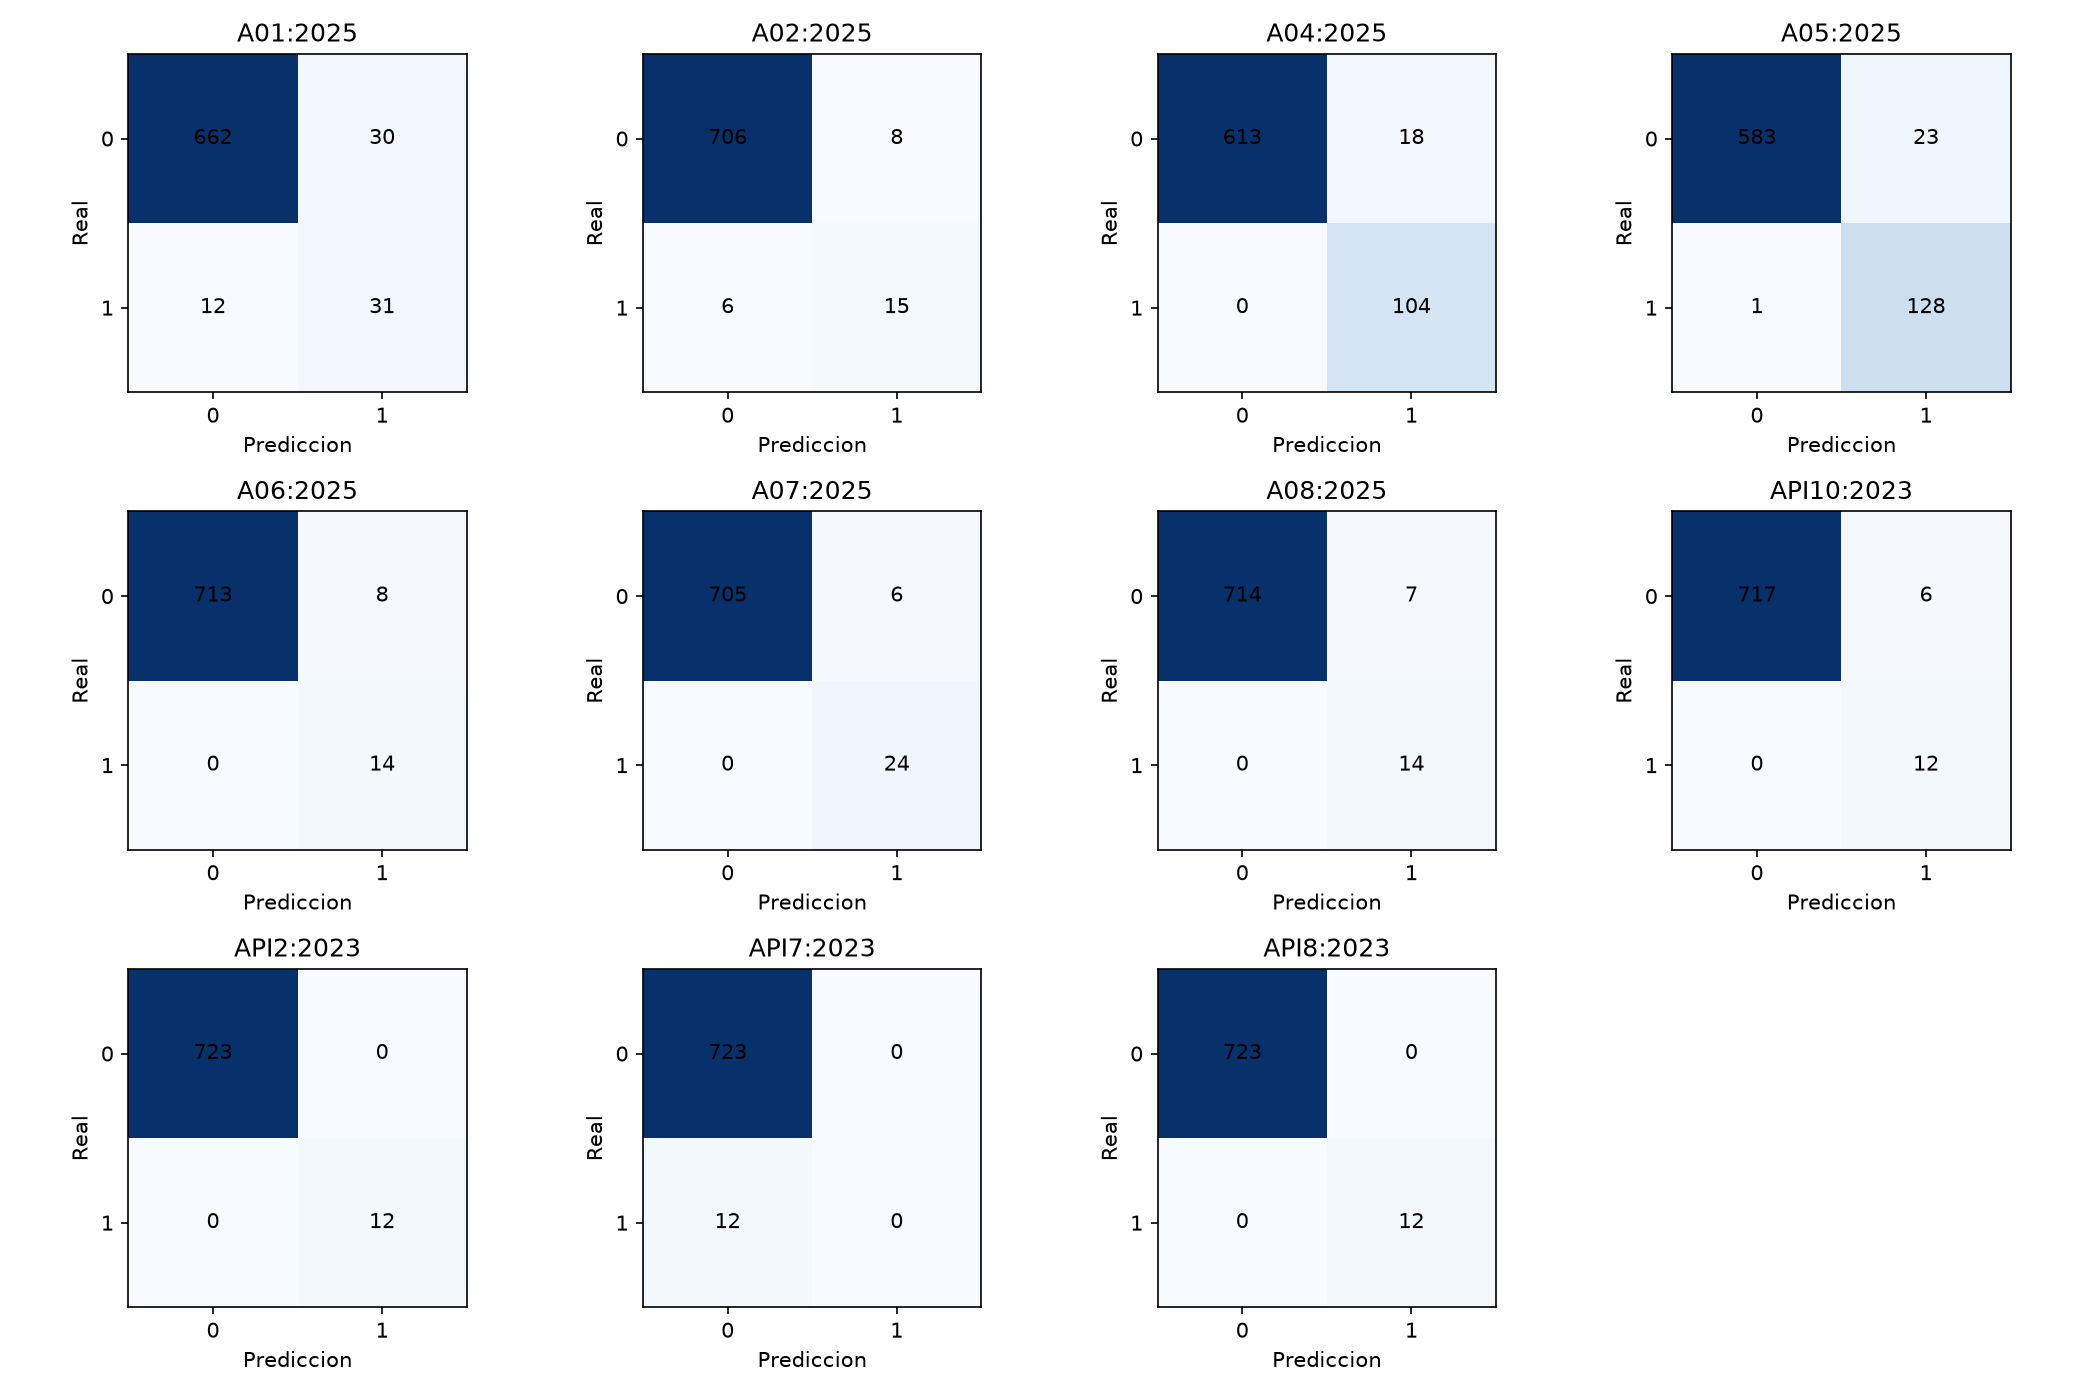

In [2]:
display(pd.DataFrame(selected['test']['per_category']).T)
display(pd.DataFrame([{ 'fuente':source, 'registros':m['records'], 'F1_macro_etiquetas_con_soporte':m['f1_macro_supported'], 'F1_micro':m['f1_micro']} for source,m in results['test_by_source'].items()]))
print('Entrenamiento / validación / prueba:', [selected[s]['f1_macro'] for s in ['train','validation','test']])
display(Image(filename=str(ROOT / 'output/evaluation/confusion_matrices.png')))

In [3]:
errors = json.loads((ROOT / 'output/evaluation/errors.json').read_text(encoding='utf-8'))
print('Registros con error:',len(errors))
display(pd.DataFrame(errors).head(8))
projects = json.loads((ROOT / 'output/evaluation/projects.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{k:v for k,v in p.items() if k in ['project','tp','fp','fn','tn','precision','recall','f1']} for p in projects]))
public_cli = json.loads((ROOT / 'output/evaluation/public_cli.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{k:v for k,v in public_cli.items() if k not in ['errors']}]))

Registros con error: 119


,id,code,false_positive,false_negative,language,scenario
0,VM-0349,with urllib.request.urlopen(request.form['name...,[],"[A01:2025, API7:2023]",Python,ssrf
1,VM-0351,with urllib.request.urlopen(request.form['id']...,[],"[A01:2025, API7:2023]",Python,ssrf
2,VM-0353,with urllib.request.urlopen(request.form['valu...,[],"[A01:2025, API7:2023]",Python,ssrf
3,VM-0355,with urllib.request.urlopen(request.form['ref'...,[],"[A01:2025, API7:2023]",Python,ssrf
4,VM-0357,with urllib.request.urlopen(request.form['item...,[],"[A01:2025, API7:2023]",Python,ssrf
5,VM-0359,with urllib.request.urlopen(request.form['toke...,[],"[A01:2025, API7:2023]",Python,ssrf
6,VM-0422,"model = yaml.load(data['name'], Loader=yaml.Sa...",[A08:2025],[],Python,deserialize
7,VM-0424,"model = yaml.load(data['id'], Loader=yaml.Safe...",[A08:2025],[],Python,deserialize


,project,tp,fp,fn,tn,precision,recall,f1
0,tienda-demo,7,0,0,7,1.0,1.0,1.0
1,logistica-demo,7,0,0,7,1.0,1.0,1.0


,sample_size,sampling,tp,fp,fn,tn,precision,recall,f1,label_f1_micro,findings,warning
0,96,"Maximo dos por fuente/escenario/estado, orden ...",33,19,14,30,0.634615,0.702128,0.666667,0.673684,55,Metricas de CLI por archivo y etiquetas; disti...


El descenso entre validación y prueba es una limitación material. Los resultados sintéticos originales se conservan en output/baseline_synthetic/ como antecedente, con otra distribución y menor cobertura, sin presentarlos como comparación controlada de mejora. La CLI puede perder controles al extraer contexto o generar falsos positivos aunque el clasificador funcione sobre fragmentos preparados. Se requiere más diversidad y una evaluación ciega en repositorios completos. Los dos incidentes documentados al final del informe ilustran impacto, no acreditan que esta herramienta los hubiera detectado.